# Experiment 3 — Sampling Methods (Iris Dataset)

**Covers:** Simple random, stratified and cluster sampling, category proportions, population/sample comparison, graph and CSV export.

**Dataset:** **Iris** – `Iris.csv` from Kaggle ([uciml/iris](https://www.kaggle.com/datasets/uciml/iris)), 150 flowers, columns `Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species`.

**Data file:** keep `Iris.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\Iris.csv")`).

**Remember:** sample() → groupby().sample() → choice() + isin() → Compare → Save.

Species is used both as strata and as clusters (Iris has no natural geographic groups), so the cluster sample contains whole species only.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Iris.csv")

## 0. Population

In [2]:
N = len(df)
n = int(0.2 * N)
mean = df["SepalLengthCm"].mean()

print("Population:", N, "Sample:", n, "Mean:", mean)

Population: 150 Sample: 30 Mean: 5.843333333333334


## 1. Simple random sampling

In [3]:
srs = df.sample(n=n, random_state=42)
print(srs.head())
print(df.sample(n=n, random_state=10).head())

      Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
73    74            6.1           2.8            4.7           1.2   
18    19            5.7           3.8            1.7           0.3   
118  119            7.7           2.6            6.9           2.3   
78    79            6.0           2.9            4.5           1.5   
76    77            6.8           2.8            4.8           1.4   

             Species  
73   Iris-versicolor  
18       Iris-setosa  
118   Iris-virginica  
78   Iris-versicolor  
76   Iris-versicolor  
      Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
87    88            6.3           2.3            4.4           1.3   
111  112            6.4           2.7            5.3           1.9   
10    11            5.4           3.7            1.5           0.2   
91    92            6.1           3.0            4.6           1.4   
49    50            5.0           3.3            1.4           0.2   

             Species

## 2. Stratified sampling using `Species`

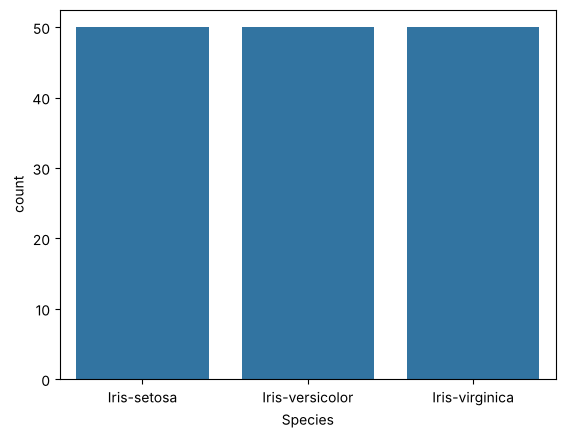

                 Population %   Sample %
Species                                 
Iris-setosa         33.333333  33.333333
Iris-versicolor     33.333333  33.333333
Iris-virginica      33.333333  33.333333


In [4]:
sns.countplot(data=df, x="Species")
plt.show()

strat = df.groupby("Species", group_keys=False).sample(
    frac=0.2, random_state=42
)

print(pd.DataFrame({
    "Population %": df["Species"].value_counts(normalize=True) * 100,
    "Sample %": strat["Species"].value_counts(normalize=True) * 100
}))

## 3. Cluster sampling using `Species`

In [5]:
clusters = df["Species"].dropna().unique()
selected = np.random.default_rng(42).choice(
    clusters, size=max(1, int(0.3 * len(clusters))), replace=False
)
cluster = df[df["Species"].isin(selected)]
print("All clusters:", clusters)
print("Selected clusters:", selected)
print("Cluster sample size:", len(cluster))

All clusters: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Selected clusters: ['Iris-setosa']
Cluster sample size: 50


## 4. Comparison table

In [6]:
samples = {"SRS": srs, "Stratified": strat, "Cluster": cluster}

result = pd.DataFrame({
    "Size": [len(s) for s in samples.values()],
    "Mean": [s["SepalLengthCm"].mean() for s in samples.values()]
}, index=samples.keys())

result["Difference"] = result["Mean"] - mean
print(result)

            Size      Mean  Difference
SRS           30  5.980000    0.136667
Stratified    30  5.883333    0.040000
Cluster       50  5.006000   -0.837333


## 5. Graph

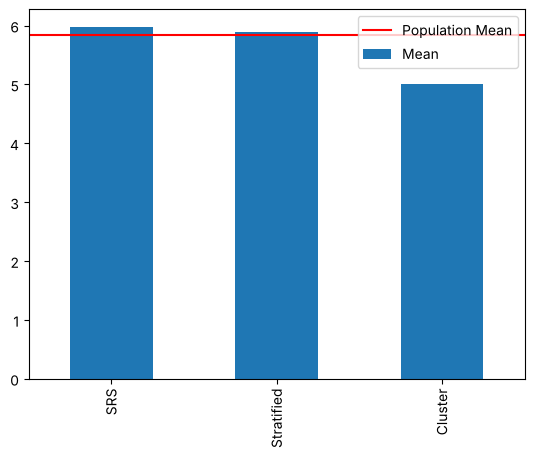

In [7]:
result["Mean"].plot(kind="bar")
plt.axhline(mean, color="red", label="Population Mean")
plt.legend()
plt.show()

## 6. Save

In [8]:
for name, sample in samples.items():
    sample.to_csv(name + ".csv", index=False)
    print("Saved", name + ".csv")

Saved SRS.csv
Saved Stratified.csv
Saved Cluster.csv


## Result / Conclusion
- Population mean `SepalLengthCm` = 5.843 (N = 150, sample size 30).
- **Stratified** sampling keeps exactly 33.3% of each species and gives the closest mean (5.883, error +0.04).
- **Simple random** sampling is also close (5.980, error +0.14).
- **Cluster** sampling selected only setosa, so its mean (5.006, error −0.84) is badly biased – clusters must be similar to the population for cluster sampling to work.